In [4]:
from pathlib import Path
import json
import sys

import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix
from xgboost import XGBClassifier

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.preprocessing import IQRClipper

print("Project folder:", project_root)

Project folder: /workspace


In [6]:
csv_path = project_root / "data/raw/student_mental_health.csv"
if not csv_path.exists():
    csv_path = project_root / "student_mental_health.csv"

if not csv_path.exists():
    raise FileNotFoundError("Put student_mental_health.csv in data/raw/")

df = pd.read_csv(csv_path)
df = df.dropna(subset=["Mental_Health_Risk"]).copy()

X = df.drop(columns=["Student_ID", "Mental_Health_Risk"])
y = df["Mental_Health_Risk"]

print("Dataset:", df.shape)
print("Input features:", X.shape[1])

Dataset: (2000, 17)
Input features: 15


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

class_mapping = {"Low": 0, "Medium": 1, "High": 2}
label_names = ["Low", "Medium", "High"]

y_train = y_train.map(class_mapping)
y_test = y_test.map(class_mapping)

print("Training students:", len(X_train))
print("Test students:", len(X_test))
print("Training labels:", y_train.value_counts().sort_index())

Training students: 1600
Test students: 400
Training labels: Mental_Health_Risk
0    528
1    528
2    544
Name: count, dtype: int64


In [8]:
numeric_columns = X_train.select_dtypes(include="number").columns.tolist()
categorical_columns = X_train.select_dtypes(exclude="number").columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("iqr", IQRClipper()),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_columns),
    ("cat", categorical_pipeline, categorical_columns)
])

print("Numeric columns:", len(numeric_columns))
print("Categorical columns:", len(categorical_columns))

Numeric columns: 10
Categorical columns: 5


In [9]:
models = {
    "SVM": SVC(kernel="rbf"),
    "XGBoost": XGBClassifier(
        objective="multi:softprob",
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=2
    )
}

parameter_grids = {
    "SVM": {
        "model__C": [0.1, 1, 10],
        "model__gamma": ["scale", 0.1, 0.01]
    },
    "XGBoost": {
        "model__max_depth": [2, 3, 4],
        "model__n_estimators": [100, 200],
        "model__learning_rate": [0.05, 0.1]
    }
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
print("Models to optimize:", list(models))

Models to optimize: ['SVM', 'XGBoost']


In [10]:
searches = {}
results = []

for name, model in models.items():
    print("Tuning:", name)

    pipeline = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("model", clone(model))
    ])

    search = GridSearchCV(
        pipeline,
        parameter_grids[name],
        cv=cv,
        scoring="f1_macro",
        n_jobs=1,
        error_score="raise"
    )
    search.fit(X_train, y_train)

    searches[name] = search
    results.append({
        "Model": name,
        "CV F1 Macro": search.best_score_,
        "Best Parameters": str(search.best_params_)
    })

comparison = pd.DataFrame(results).sort_values(
    "CV F1 Macro", ascending=False
).reset_index(drop=True)

display(comparison.round(3))

Tuning: SVM
Tuning: XGBoost


,Model,CV F1 Macro,Best Parameters
0,SVM,0.738,"{'model__C': 10, 'model__gamma': 0.01}"
1,XGBoost,0.705,"{'model__learning_rate': 0.1, 'model__max_dept..."


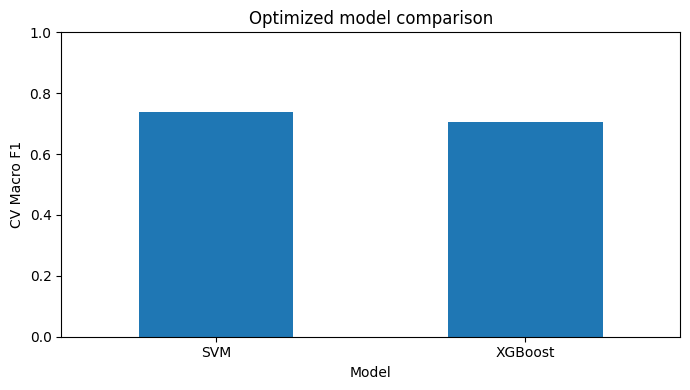

Selected model: SVM
Best settings: {'model__C': 10, 'model__gamma': 0.01}


In [11]:
comparison.plot(
    x="Model", y="CV F1 Macro", kind="bar",
    figsize=(7, 4), legend=False
)
plt.ylim(0, 1)
plt.ylabel("CV Macro F1")
plt.title("Optimized model comparison")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

best_model_name = comparison.loc[0, "Model"]
best_pipeline = searches[best_model_name].best_estimator_

print("Selected model:", best_model_name)
print("Best settings:", searches[best_model_name].best_params_)

In [12]:
y_pred = best_pipeline.predict(X_test)

test_metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "precision_macro": precision_score(y_test, y_pred, average="macro", zero_division=0),
    "recall_macro": recall_score(y_test, y_pred, average="macro", zero_division=0),
    "f1_macro": f1_score(y_test, y_pred, average="macro", zero_division=0)
}

print("Selected model:", best_model_name)
for name, value in test_metrics.items():
    print(f"{name}: {value:.3f}")

print("Classification report:")
print(classification_report(
    y_test, y_pred,
    labels=[0, 1, 2],
    target_names=label_names,
    zero_division=0
))

Selected model: SVM
accuracy: 0.748
precision_macro: 0.741
recall_macro: 0.747
f1_macro: 0.743
Classification report:
              precision    recall  f1-score   support

         Low       0.79      0.83      0.81       132
      Medium       0.64      0.57      0.60       132
        High       0.80      0.85      0.82       136

    accuracy                           0.75       400
   macro avg       0.74      0.75      0.74       400
weighted avg       0.74      0.75      0.74       400



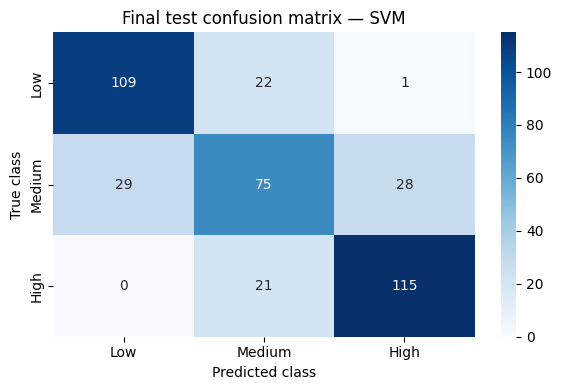

In [14]:
matrix = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])

plt.figure(figsize=(6, 4))
sns.heatmap(
    matrix, annot=True, fmt="d", cmap="Blues",
    xticklabels=label_names, yticklabels=label_names
)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title(f"Final test confusion matrix — {best_model_name}")
plt.tight_layout()
plt.show()

In [15]:
errors = pd.DataFrame({
    "True": y_test.map({0: "Low", 1: "Medium", 2: "High"}),
    "Predicted": pd.Series(y_pred, index=y_test.index).map(
        {0: "Low", 1: "Medium", 2: "High"}
    )
})

errors = errors[errors["True"] != errors["Predicted"]]
print("Incorrect predictions:", len(errors), "out of", len(y_test))
print("Most frequent confusions:")
display(errors.value_counts().rename("Count").reset_index())

Incorrect predictions: 101 out of 400
Most frequent confusions:


,True,Predicted,Count
0,Medium,Low,29
1,Medium,High,28
2,Low,Medium,22
3,High,Medium,21
4,Low,High,1


In [16]:
models_dir = project_root / "models"
reports_dir = project_root / "reports"
models_dir.mkdir(parents=True, exist_ok=True)
reports_dir.mkdir(parents=True, exist_ok=True)

model_path = models_dir / "mental_health_pipeline.joblib"
joblib.dump(best_pipeline, model_path)

comparison.to_csv(reports_dir / "model_comparison_day4.csv", index=False)

summary = {
    "selected_model": best_model_name,
    "cv_f1_macro": float(comparison.loc[0, "CV F1 Macro"]),
    "best_parameters": searches[best_model_name].best_params_,
    "test_metrics": {name: float(value) for name, value in test_metrics.items()},
    "class_mapping": class_mapping,
    "confusion_matrix": matrix.tolist(),
    "note": "Educational prototype with simulated data; not for clinical use."
}

with open(reports_dir / "model_metrics_day4.json", "w", encoding="utf-8") as file:
    json.dump(summary, file, indent=2)

print("Saved model:", model_path)
print("Saved evaluation summary in reports/")

Saved model: /workspace/models/mental_health_pipeline.joblib
Saved evaluation summary in reports/
